# 🌦️ Weather Forecast - Time Series Analysis

Questo notebook guida attraverso tutte le fasi per la previsione del meteo usando tecniche di time series.

## 1. Import Required Libraries

In [24]:
# Import delle librerie necessarie
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

## 2. Load and Explore Weather Data

In [25]:
# Carica i dati meteo (modifica il nome del file se necessario)
df = pd.read_csv('../data/seattle-weather.csv')
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
print('Colonne:', df.columns.tolist())
print(df.head())
print(df.describe())
print('Valori mancanti per colonna:')
print(df.isnull().sum())

Colonne: ['precipitation', 'temp_max', 'temp_min', 'wind', 'weather']
            precipitation  temp_max  temp_min  wind  weather
date                                                        
2012-01-01            0.0      12.8       5.0   4.7  drizzle
2012-01-02           10.9      10.6       2.8   4.5     rain
2012-01-03            0.8      11.7       7.2   2.3     rain
2012-01-04           20.3      12.2       5.6   4.7     rain
2012-01-05            1.3       8.9       2.8   6.1     rain
       precipitation     temp_max     temp_min         wind
count    1461.000000  1461.000000  1461.000000  1461.000000
mean        3.029432    16.439083     8.234771     3.241136
std         6.680194     7.349758     5.023004     1.437825
min         0.000000    -1.600000    -7.100000     0.400000
25%         0.000000    10.600000     4.400000     2.200000
50%         0.000000    15.600000     8.300000     3.000000
75%         2.800000    22.200000    12.200000     4.000000
max        55.900000   

## 3. Visualize Time Series Data

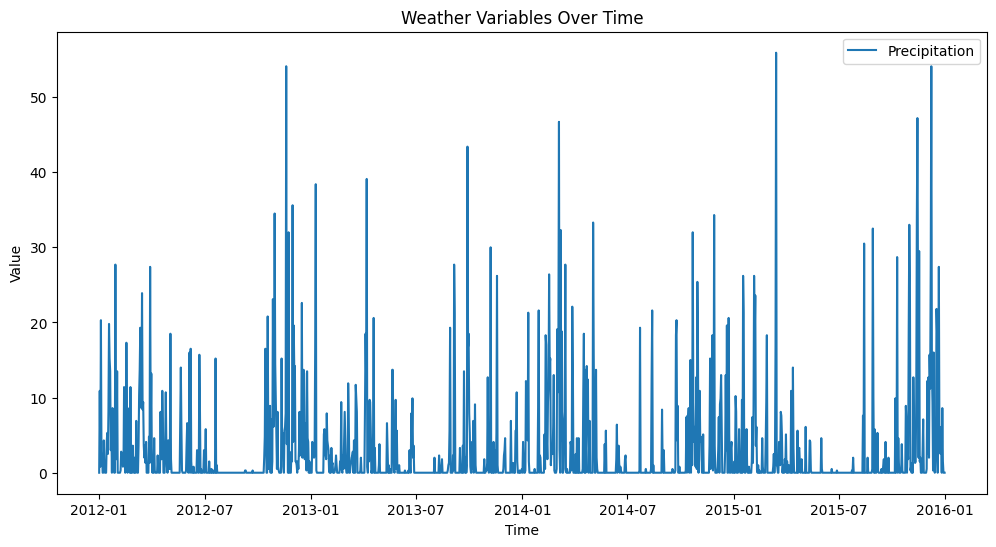

In [26]:
# Visualizza le variabili meteo nel tempo (es. temperatura, umidità)
plt.figure(figsize=(12,6))
for col in ['temperature', 'humidity', 'precipitation']:
    if col in df.columns:
        plt.plot(df.index, df[col], label=col.capitalize())
plt.legend()
plt.title('Weather Variables Over Time')
plt.xlabel('Time')
plt.ylabel('Value')
plt.show()

## 4. Preprocess Data for Forecasting

In [27]:
# Gestione valori mancanti e creazione train/test split
df = df.fillna(method='ffill').fillna(method='bfill')
target = 'temperature' if 'temperature' in df.columns else df.columns[0]
data = df[target].values
train_size = int(len(data) * 0.8)
train, test = data[:train_size], data[train_size:]

/tmp/ipykernel_27496/3118306698.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


## 5. Build and Train Time Series Forecasting Model

In [28]:
# Modello ARIMA per previsione della variabile target
model = ARIMA(train, order=(3,1,2))
model_fit = model.fit()
preds = model_fit.forecast(steps=len(test))

## 6. Evaluate Model Performance

MAE: 4.34
RMSE: 7.98


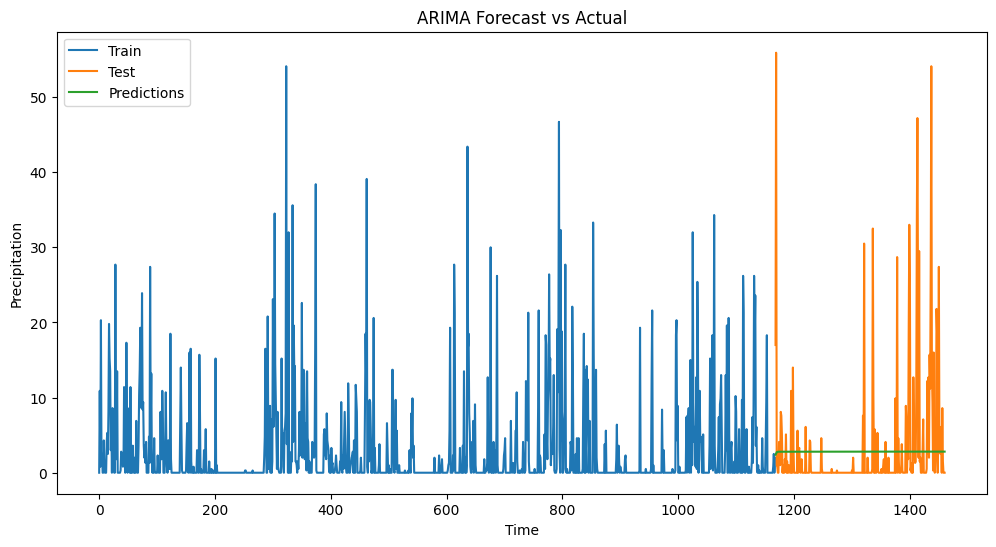

In [29]:
# Valutazione delle performance del modello
mae = mean_absolute_error(test, preds)
rmse = np.sqrt(mean_squared_error(test, preds))
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
plt.figure(figsize=(12,6))
plt.plot(range(len(train)), train, label='Train')
plt.plot(range(len(train), len(train)+len(test)), test, label='Test')
plt.plot(range(len(train), len(train)+len(test)), preds, label='Predictions')
plt.legend()
plt.title('ARIMA Forecast vs Actual')
plt.xlabel('Time')
plt.ylabel(target.capitalize())
plt.show()

## 7. Make Future Weather Predictions

Previsioni per i prossimi giorni: [4.80126462 5.68173897 6.37568786 6.58912231 6.7106477  6.7513889
 6.7752493 ]


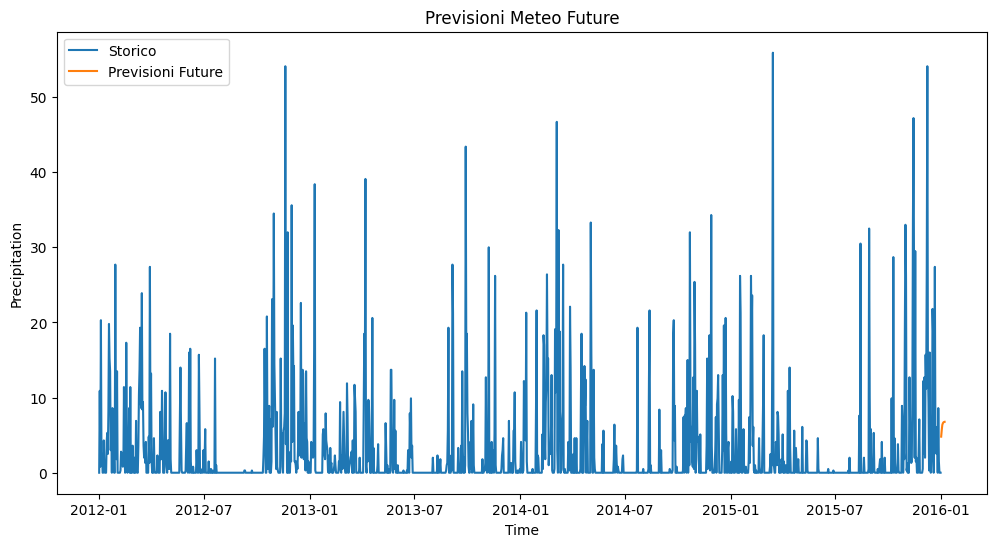

In [30]:
# Previsione dei valori futuri (es. prossimi 7 giorni)
future_steps = 7
model_full = ARIMA(data, order=(3,1,2)).fit()
future_preds = model_full.forecast(steps=future_steps)
print('Previsioni per i prossimi giorni:', future_preds)
plt.figure(figsize=(12,6))
plt.plot(df.index, data, label='Storico')
future_index = pd.date_range(df.index[-1], periods=future_steps+1, freq='D')[1:] if hasattr(df.index, 'freq') or isinstance(df.index, pd.DatetimeIndex) else range(len(data), len(data)+future_steps)
plt.plot(future_index, future_preds, label='Previsioni Future')
plt.legend()
plt.title('Previsioni Meteo Future')
plt.xlabel('Time')
plt.ylabel(target.capitalize())
plt.show()

## 8. Advanced Feature Engineering & Model Comparison

/tmp/ipykernel_27496/1936521676.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill')


            precipitation  temp_max  temp_min  wind  weather temp_lag1  \
date                                                                     
2012-01-01            0.0      12.8       5.0   4.7  drizzle      None   
2012-01-02           10.9      10.6       2.8   4.5     rain      None   
2012-01-03            0.8      11.7       7.2   2.3     rain      None   
2012-01-04           20.3      12.2       5.6   4.7     rain      None   
2012-01-05            1.3       8.9       2.8   6.1     rain      None   
2012-01-06            2.5       4.4       2.2   2.2     rain      None   
2012-01-07            0.0       7.2       2.8   2.3     rain      None   
2012-01-08            0.0      10.0       2.8   2.0      sun      None   
2012-01-09            4.3       9.4       5.0   3.4     rain      None   
2012-01-10            1.0       6.1       0.6   3.4     rain      None   

           temp_roll7  
date                   
2012-01-01       None  
2012-01-02       None  
2012-01-03     

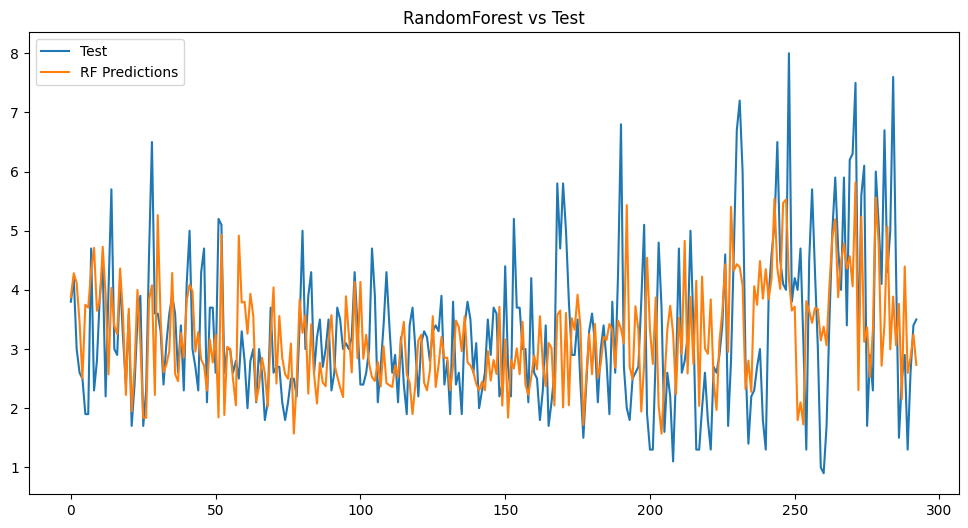

In [31]:
# Feature engineering: aggiungi lag e rolling mean
df['temp_lag1'] = df['temperature'].shift(1) if 'temperature' in df.columns else None
df['temp_roll7'] = df['temperature'].rolling(window=7).mean() if 'temperature' in df.columns else None
df = df.fillna(method='bfill')
print(df[['temperature','temp_lag1','temp_roll7']].head(10) if 'temperature' in df.columns else df.head(10))

# Confronto modelli: ARIMA vs RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
# Usa solo colonne numeriche per RandomForest
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
features = [col for col in ['temp_lag1','temp_roll7'] if col in numeric_cols]
if not features:
    features = numeric_cols[:-1]  # Escludi la colonna target se necessario
X = df[features]
y = df['temperature'] if 'temperature' in df.columns else df[numeric_cols[-1]]
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)
print('RandomForest MAE:', mean_absolute_error(y_test, rf_preds))
print('RandomForest RMSE:', np.sqrt(mean_squared_error(y_test, rf_preds)))
plt.figure(figsize=(12,6))
plt.plot(y_test.values, label='Test')
plt.plot(rf_preds, label='RF Predictions')
plt.legend()
plt.title('RandomForest vs Test')
plt.show()

## 9. Dashboard Finale

ARIMA MAE: 4.341330626375056
ARIMA RMSE: 7.9769055181452595
RandomForest MAE: 0.9644064059660475
RandomForest RMSE: 1.2618070340807872


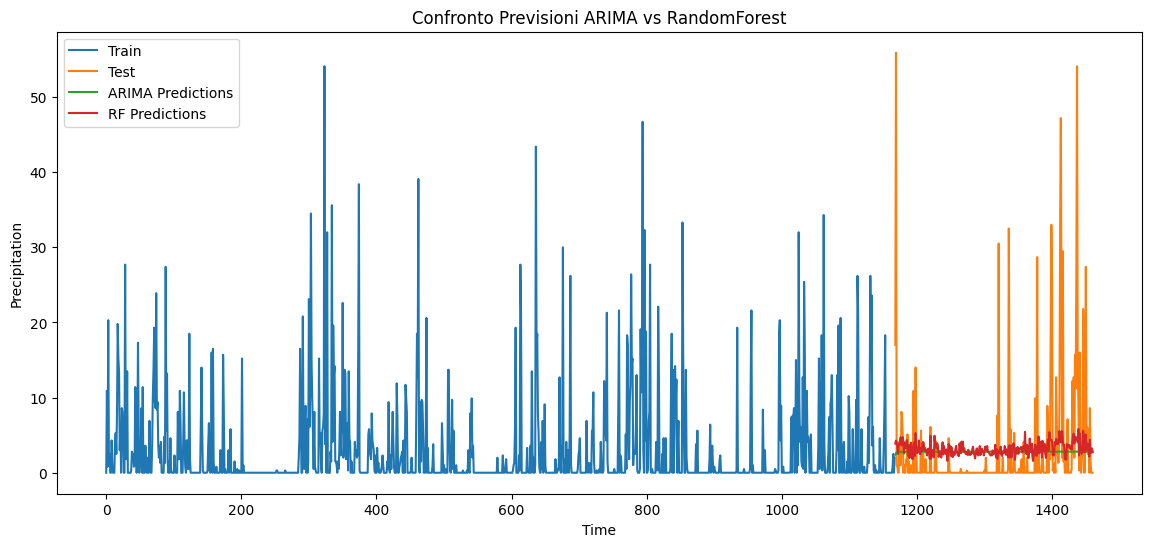

In [32]:
# Dashboard finale: riepilogo metriche e grafici
print('ARIMA MAE:', mae)
print('ARIMA RMSE:', rmse)
print('RandomForest MAE:', mean_absolute_error(y_test, rf_preds))
print('RandomForest RMSE:', np.sqrt(mean_squared_error(y_test, rf_preds)))
plt.figure(figsize=(14,6))
plt.plot(range(len(train)), train, label='Train')
plt.plot(range(len(train), len(train)+len(test)), test, label='Test')
plt.plot(range(len(train), len(train)+len(test)), preds, label='ARIMA Predictions')
plt.plot(range(len(train), len(train)+len(test)), rf_preds, label='RF Predictions')
plt.legend()
plt.title('Confronto Previsioni ARIMA vs RandomForest')
plt.xlabel('Time')
plt.ylabel(target.capitalize())
plt.show()